In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## Exercício — Simulação da distribuição normal

Considere a densidade da normal padrão,

$$
f(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2},
$$

e, para $x>0$, utilize como distribuição proposta uma exponencial com taxa $1$,

$$
g(x)=e^{-x}, \qquad x\geq 0.
$$

1. Para aplicar o método de rejeição-aceitação, determine a constante

$$
c=\sup_{x>0}\frac{f(x)}{g(x)}.
$$

Para isso, encontre o ponto de máximo da razão $f(x)/g(x)$ e obtenha a expressão da probabilidade de aceitação

$$
\frac{f(x)}{c\,g(x)}.
$$

2. A partir do resultado anterior, implemente em Python um algoritmo de rejeição-aceitação para gerar uma amostra de tamanho $n$ da distribuição de $|N(0,1)|$.

3. Utilize sinais aleatórios independentes, com probabilidades iguais de serem positivos ou negativos, para transformar essa amostra em uma amostra de

$$
N(0,1).
$$

Gere também uma amostra de mesmo tamanho utilizando `numpy.random.normal` e compare as duas distribuições por meio de histogramas.

4. Suponha agora que você saiba gerar $Z\sim N(0,1)$. Como você pode utilizar $Z$ para gerar

$$
X\sim N(\mu,\sigma^2)?
$$

Implemente essa transformação para gerar uma amostra de tamanho $n$ de $N(\mu,\sigma^2)$.

5. Gere também uma amostra de $N(\mu,\sigma^2)$ utilizando `numpy.random.normal` e compare os histogramas das duas amostras.

6. Durante a simulação, registre o número total de propostas geradas e calcule a taxa empírica de aceitação,

$$
\widehat{p}_{\text{aceitação}}
=
\frac{\text{número de valores aceitos}}
{\text{número total de propostas}}.
$$

Compare esse valor com a taxa teórica de aceitação do método,

$$
p_{\text{aceitação}}=\frac{1}{c},
$$

onde $c$ é a constante obtida anteriormente. Os valores observado e esperado são compatíveis?

In [ ]:
def f(x):
  return (2*(np.exp((-x**2)/2))/np.sqrt(2*np.pi))
def g(x):
  return np.exp(-x)


Analíticamente, olhando para a razão, temos que

$$
c=\frac{1}{\sqrt{2\pi}}e^{x-x^2/2},
$$

Para achar o ponto de máximo, derivamos apenas a parte que compõe x, obtendo:

$$
h'(x) = d/dx (x-(x²/2)) = 1 - x
$$

e encontrando o valor que resulta na expressão dar em 0, tendo então:

$$
h'(x)= 1 - x = 0
$$
$$
x =1
$$

Definimos c então como:

3.0303030303030303
0.7601734505331403


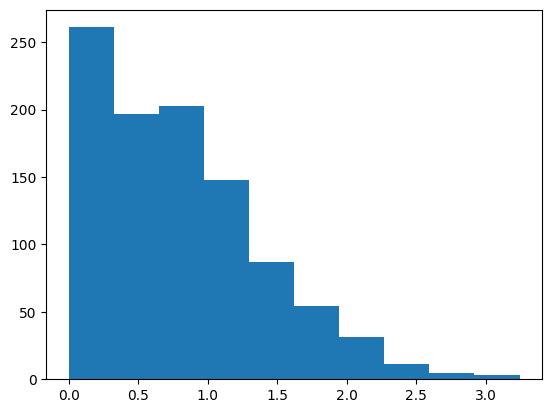

In [ ]:
c = np.sqrt(2/np.pi)*np.exp(1/2)
rejeitado = 0
aceito = 0
# Normal modular
amostra_1 = []
N = 1000
for i in range(N):
  U = np.random.uniform()
  u = np.random.uniform()
  y = -np.log(1-u)
  while U*c*g(y) > f(y):
    rejeitado += 1
    U = np.random.uniform()
    u = np.random.uniform()
    y = -np.log(1-u)
  X = y
  aceito +=1
  amostra_1.append(X)
plt.hist(amostra_1)


Text(0.5, 1.0, 'Dsitribuição Numpy')

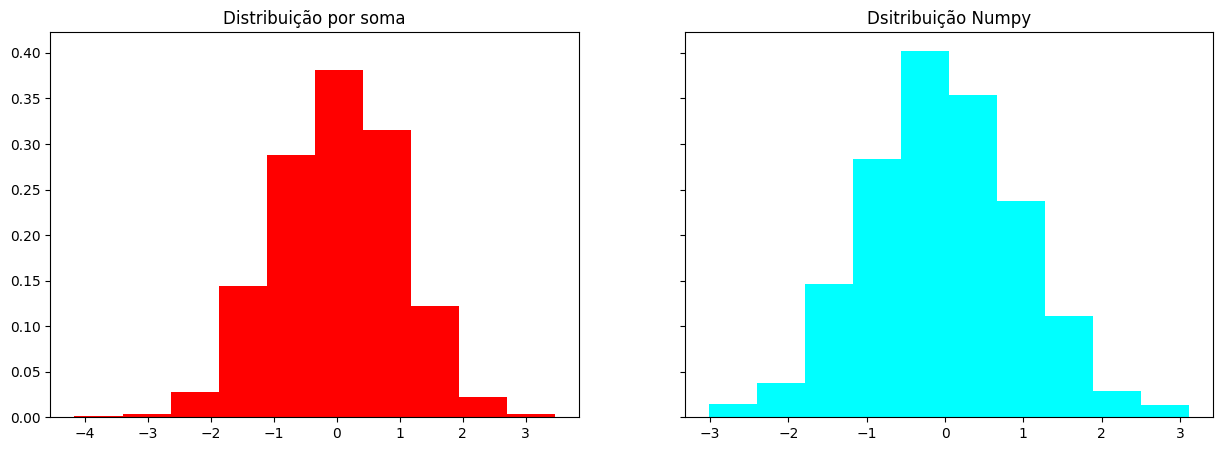

In [ ]:
c = np.sqrt(2/np.pi)*np.exp(1/2)
amostra_2 = []
N = 1000
for i in range(N):
  U = np.random.uniform()
  u = np.random.uniform()
  y = -np.log(1-u)
  while U*c*g(y) > f(y):
    U = np.random.uniform()
    u = np.random.uniform()
    y = -np.log(1-u)
  sorteio = np.random.uniform()
  if sorteio > 0.5 :
    X = y
  else:
    X = -y
  amostra_2.append(X)
normal_numpy = np.random.normal(0, 1, 1000)
fig, axs= plt.subplots(1, 2, figsize= (15,5), sharey = True)
axs[0].hist(amostra_2, density = True, color = "Red")
axs[0].set_title('Distribuição por soma')
axs[1].hist(normal_numpy, density = True, color = "Cyan")
axs[1].set_title('Dsitribuição Numpy')

Text(0.5, 1.0, 'Distribuição Numpy')

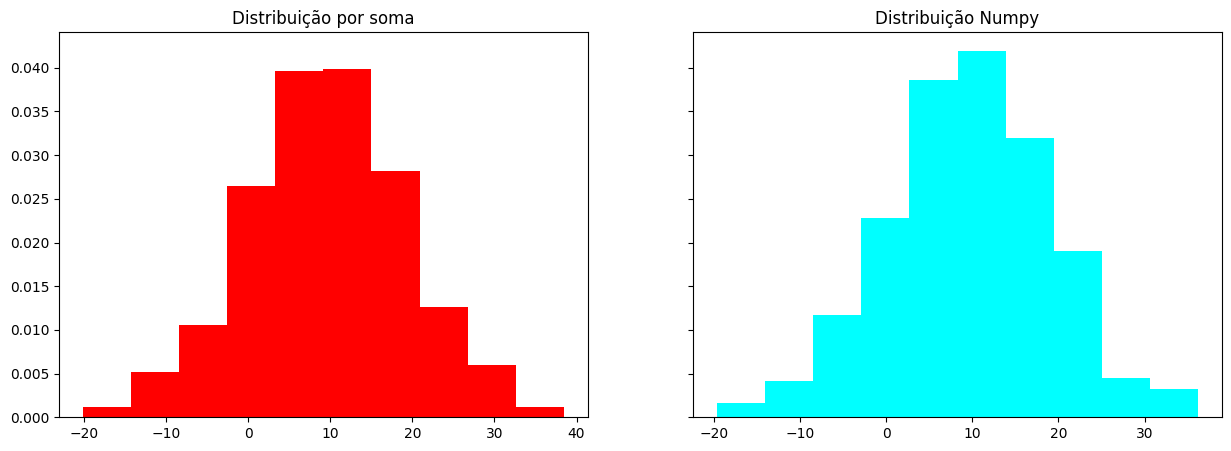

In [ ]:
c = np.sqrt(2/np.pi)*np.exp(1/2)
amostra_3 = []
mi = 10
sigma_2 = 90
N = 1000
for i in range(N):
  U = np.random.uniform()
  u = np.random.uniform()
  y = -np.log(1-u)
  while U*c*g(y) > f(y):
    U = np.random.uniform()
    u = np.random.uniform()
    y = -np.log(1-u)
  sorteio = np.random.uniform()
  if sorteio > 0.5 :
    X = y
  else:
    X = -y
  amostra_3.append((np.sqrt(sigma_2)*X)+mi)
normal_numpy = np.random.normal(mi, np.sqrt(sigma_2), 1000)
fig, axs= plt.subplots(1, 2, figsize= (15,5), sharey = True)
axs[0].hist(amostra_3, density = True, color = "Red")
axs[0].set_title('Distribuição por soma')
axs[1].hist(normal_numpy, density = True, color = "Cyan")
axs[1].set_title('Distribuição Numpy')



In [ ]:
c = np.sqrt(2/np.pi)*np.exp(1/2)
rejeitado = 0
aceito = 0
amostra_2 = []
N = 1000
for i in range(N):
  U = np.random.uniform()
  u = np.random.uniform()
  y = -np.log(1-u)
  while U*c*g(y) > f(y):
    rejeitado += 1
    U = np.random.uniform()
    u = np.random.uniform()
    y = -np.log(1-u)
  sorteio = np.random.uniform()
  if sorteio > 0.5 :
    X = y
  else:
    X = -y
  aceito +=1
  amostra_2.append(X)
p_aceitacao = aceito / (aceito+rejeitado)
print(p_aceitacao)
p_aceitacao_teor = 1/c
print(p_aceitacao_teor)

0.7722007722007722
0.7601734505331403
